In [1]:
from sklearn.datasets import load_breast_cancer
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Step 1: Load the Breast Cancer dataset
data = load_breast_cancer()

In [2]:
import pandas as pd
# Convert dataset into a DataFrame
df = pd.DataFrame(data.data, columns=data.feature_names)
df.info()
# Display all column names
print(df.columns)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 30 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         5

In [3]:
X = data.data
y = data.target

# Step 2: Split the data into train and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Step 3: Create and train the Gradient Boosting model
model = GradientBoostingClassifier(
    n_estimators=250,     # Number of boosting stages
    learning_rate=0.1,    # Step size shrinkage
    max_depth=5,          # Max depth of each tree
    random_state=42
)
model.fit(X_train, y_train)

# Step 4: Make predictions
y_pred = model.predict(X_test)

# Step 5: Evaluate the model
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))


Accuracy: 0.9649122807017544

Classification Report:
               precision    recall  f1-score   support

           0       0.98      0.93      0.95        43
           1       0.96      0.99      0.97        71

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114

Confusion Matrix:
 [[40  3]
 [ 1 70]]


In [4]:
# Take 5 sample records from the test dataset
sample = X_test[:5]

# Actual values
print("Actual values:", y_test[:5])

# Predicted values
predictions = model.predict(sample)
print("Predicted values:", predictions)

# Convert numerical predictions into class names
print("Predicted classes:", data.target_names[predictions])

Actual values: [1 0 0 1 1]
Predicted values: [1 0 0 1 1]
Predicted classes: ['benign' 'malignant' 'malignant' 'benign' 'benign']


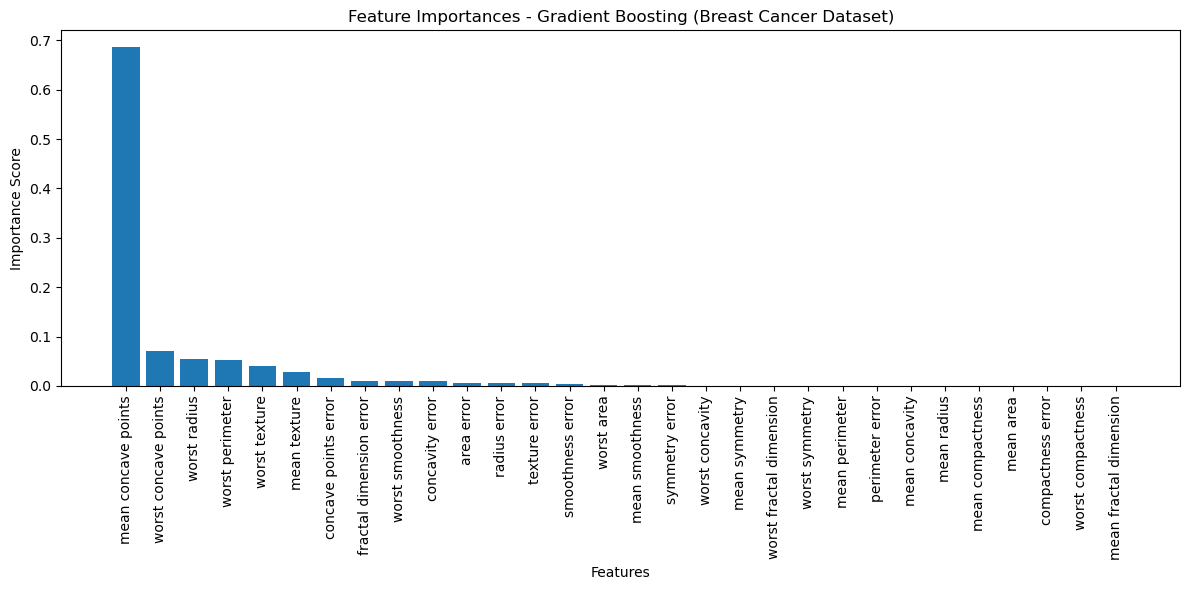

In [5]:
import matplotlib.pyplot as plt
import numpy as np

# Get feature importances from the model
importances = model.feature_importances_
feature_names = data.feature_names

# Sort features by importance
indices = np.argsort(importances)[::-1]

# Plot the feature importances
plt.figure(figsize=(12, 6))
plt.title("Feature Importances - Gradient Boosting (Breast Cancer Dataset)")
plt.bar(range(X.shape[1]), importances[indices], align="center")
plt.xticks(range(X.shape[1]), feature_names[indices], rotation=90)
plt.xlabel("Features")
plt.ylabel("Importance Score")
plt.tight_layout()
plt.show()
